In [1]:
from sklearn.datasets import load_digits
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
digits = load_digits()
digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7'

In [3]:
print("Images shape:", digits.images.shape)
print("Data shape:", digits.data.shape)
print("Target shape:", digits.target.shape)
print("Target classes:", np.unique(digits.target))

Images shape: (1797, 8, 8)
Data shape: (1797, 64)
Target shape: (1797,)
Target classes: [0 1 2 3 4 5 6 7 8 9]


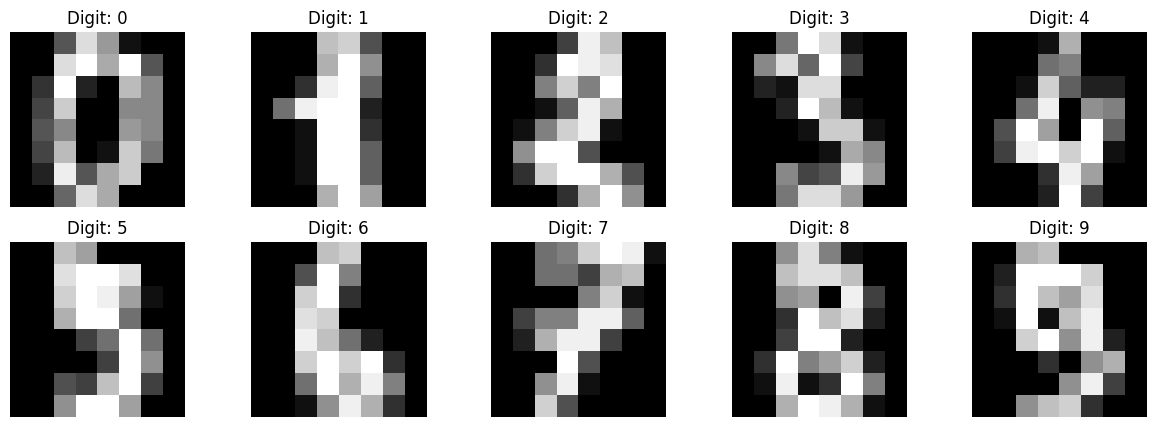

In [4]:
fig, axes = plt.subplots(2,5, figsize=(15,5))
for digit_class, ax in enumerate(axes.flat):
    image_index = np.where(digits.target == digit_class)[0][0]

    ax.imshow(digits.images[image_index], cmap='gray')
    ax.set_title(f"Digit: {digit_class}")
    ax.axis("off")

plt.show()

In [5]:
X = digits.data
y = digits.target

df = pd.DataFrame(X)
df['target'] = y
df.head()

,0,1,2,3,4,5,6,7,8,9,...,55,56,57,58,59,60,61,62,63,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


In [6]:
df.shape

(1797, 65)

In [7]:
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())
print("Mean pixel value:", X.mean())
print("Standard deviation:", X.std())

Minimum pixel value: 0.0
Maximum pixel value: 16.0
Mean pixel value: 4.884164579855314
Standard deviation: 6.016787548672236


In [8]:
class_counts = pd.Series(y).value_counts().sort_index()
class_counts

0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64

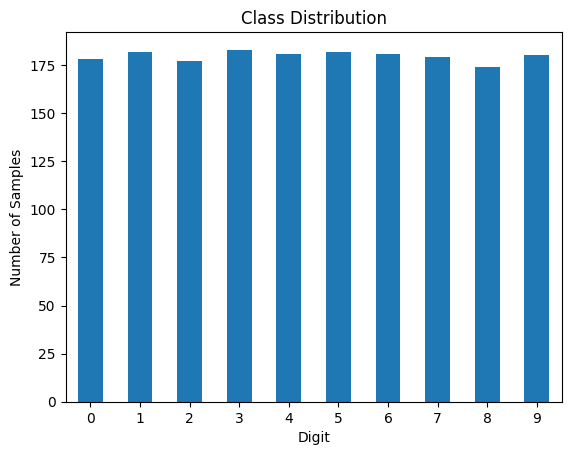

In [9]:
class_counts.plot(kind = 'bar')
plt.xlabel("Digit")
plt.ylabel("Number of Samples")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()

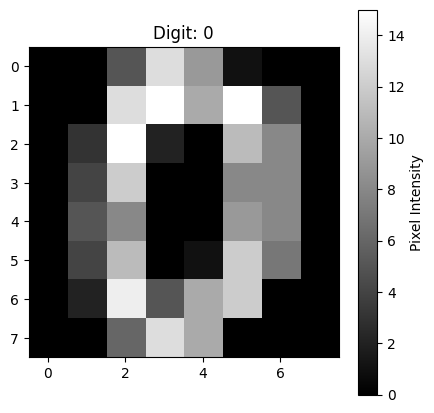

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


In [10]:
plt.figure(figsize=(5, 5))
plt.imshow(digits.images[0], cmap='gray')
plt.colorbar(label='Pixel Intensity')
plt.title(f"Digit: {digits.target[0]}")
plt.show()

print(digits.images[0])

## Pixel Feature Analysis

Each image is represented by 64 pixel intensity values, corresponding to its 8×8 grayscale representation. Pixel values range from 0 to 16, with a mean of approximately 4.88 and a standard deviation of 6.02.

The class distribution is nearly balanced, with sample counts ranging from 174 to 183 across the ten digit classes. Therefore, significant class imbalance is not expected to be a major source of bias during model evaluation.

Pixel values represent spatial intensity patterns rather than independent semantic features. Their positions are important because the arrangement of bright and dark pixels determines the visual structure of each handwritten digit.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X , y , test_size=0.2 , random_state=123 , stratify = y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1437, 64)
X_test: (360, 64)
y_train: (1437,)
y_test: (360,)


In [12]:
# Investigate Feature Scaling
from sklearn.preprocessing import MinMaxScaler , StandardScaler

standard_scaler = StandardScaler()
X_train_standard = standard_scaler.fit_transform(X_train)
X_test_standard = standard_scaler.transform(X_test)

minmax_scaler = MinMaxScaler()
X_train_minmax = minmax_scaler.fit_transform(X_train)
X_test_minmax = minmax_scaler.transform(X_test)

In [13]:
print("Original data:")
print("Mean:", X_train.mean())
print("Std:", X_train.std())
print("Min:", X_train.min())
print("Max:", X_train.max())

print("\nStandard Scaled:")
print("Mean:", X_train_standard.mean())
print("Std:", X_train_standard.std())
print("Min:", X_train_standard.min())
print("Max:", X_train_standard.max())

print("\nMin-Max Scaled:")
print("Mean:", X_train_minmax.mean())
print("Std:", X_train_minmax.std())
print("Min:", X_train_minmax.min())
print("Max:", X_train_minmax.max())

Original data:
Mean: 4.887656576200418
Std: 6.018737476099753
Min: 0.0
Max: 16.0

Standard Scaled:
Mean: 3.3994302772099435e-18
Std: 0.9762812094883316
Min: -3.0034428944262612
Max: 37.89459064299301

Min-Max Scaled:
Mean: 0.30746115280953484
Std: 0.37677382368773127
Min: 0.0
Max: 1.0


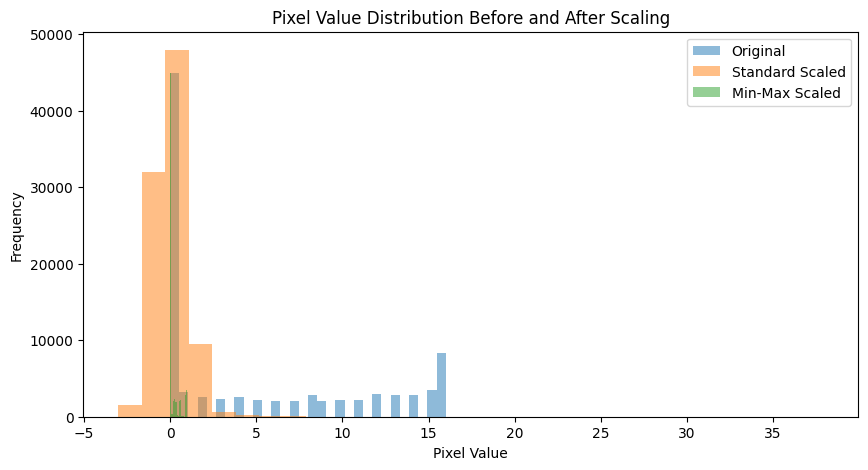

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(X_train.flatten(), bins=30, alpha=0.5, label="Original")
plt.hist(X_train_standard.flatten(), bins=30, alpha=0.5, label="Standard Scaled")
plt.hist(X_train_minmax.flatten(), bins=30, alpha=0.5, label="Min-Max Scaled")

plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("Pixel Value Distribution Before and After Scaling")
plt.legend()
plt.show()

## Feature Scaling Analysis

The original pixel values range from 0 to 16. Two scaling techniques were investigated: StandardScaler and MinMaxScaler.

StandardScaler transforms each pixel feature independently to have approximately zero mean and unit variance. However, the overall standard deviation of the flattened dataset is not exactly one because some pixel features have zero variance.

MinMaxScaler maps pixel values to the range [0, 1], preserving their relative ordering while changing their numerical scale.

The histogram shows a high concentration of values near zero, mainly due to the large number of background pixels. Standardization also produces some relatively large values, indicating that certain pixel intensities are far from their corresponding feature means.

The actual impact of scaling on classification performance will be evaluated by comparing model accuracy across the original and scaled datasets.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [16]:
datasets = {
    "Original": (X_train, X_test),
    "Standard Scaled": (X_train_standard, X_test_standard),
    "Min-Max Scaled": (X_train_minmax, X_test_minmax)
}

scaling_results = []

for dataset_name, (Xtr, Xte) in datasets.items():

    lr = LogisticRegression(max_iter=2000)
    lr.fit(Xtr, y_train)
    lr_pred = lr.predict(Xte)

    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(Xtr, y_train)
    knn_pred = knn.predict(Xte)

    scaling_results.append({
        "Scaling": dataset_name,
        "Logistic Regression": accuracy_score(y_test, lr_pred),
        "KNN": accuracy_score(y_test, knn_pred)
    })

scaling_df = pd.DataFrame(scaling_results)
print(scaling_df.round(4))

           Scaling  Logistic Regression     KNN
0         Original               0.9694  0.9917
1  Standard Scaled               0.9750  0.9833
2   Min-Max Scaled               0.9806  0.9917


## Effect of Feature Scaling on Classification

The impact of feature scaling was investigated using Logistic Regression and KNN.

For Logistic Regression, MinMaxScaler achieved the highest accuracy (98.06%), compared with 97.50% using StandardScaler and 96.94% on the original data.

KNN achieved its best accuracy (99.17%) on both the original and Min-Max scaled data. Standard scaling resulted in a slightly lower accuracy of 98.33%.

These results indicate that the effect of scaling depends on the classification algorithm. Min-Max scaling provided a small improvement for Logistic Regression, whereas KNN performed equally well on the original and Min-Max scaled features.

Since the comparison is based on a single train-test split, the observed differences should not be considered definitive evidence of generalization performance.

In [17]:
# Train the Four Classification Models
# We chose the best scaling answer's model

lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_train_minmax, y_train)

lr_predictions = lr_model.predict(X_test_minmax)

In [18]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

knn_predictions = knn_model.predict(X_test)

In [19]:
# for evaluating random forest and decision tree there is no need to scale the data
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
models = {
    "Logistic Regression": lr_predictions,
    "KNN": knn_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions
}

results = []

for name, predictions in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro"),
        "Recall": recall_score(y_test, predictions, average="macro"),
        "F1-score": f1_score(y_test, predictions, average="macro")
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-score
0  Logistic Regression    0.9806     0.9813  0.9803    0.9804
1                  KNN    0.9917     0.9921  0.9914    0.9916
2        Decision Tree    0.8833     0.8855  0.8829    0.8835
3        Random Forest    0.9917     0.9920  0.9915    0.9916


In [22]:
for name, predictions in models.items():
    print(f"\n{name}")
    print(classification_report(y_test, predictions))


Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      0.97      0.95        36
           2       0.97      0.97      0.97        35
           3       0.97      0.97      0.97        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       1.00      0.97      0.99        36
           8       1.00      0.91      0.96        35
           9       0.95      1.00      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360


KNN
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      1.00      0.97        36
           2       1.00      0.97      0.99        3

## Model Evaluation

All four classifiers were evaluated using Accuracy, Macro Precision, Macro Recall, and Macro F1-score.

KNN and Random Forest achieved the highest accuracy of 99.17%, with nearly identical F1-scores of 99.16%. KNN obtained slightly higher precision, while Random Forest achieved marginally higher recall.

Logistic Regression also performed well, reaching 98.06% accuracy. In contrast, Decision Tree achieved 88.33%, making it the weakest classifier in this experiment.

The class-level evaluation reveals that Decision Tree had more difficulty recognizing digits 2, 8, and 9. KNN and Random Forest showed more consistent performance across the ten classes, although digit 8 remained relatively challenging.

Overall, KNN and Random Forest demonstrated the strongest classification performance, with no substantial difference between their evaluation metrics on this test set.

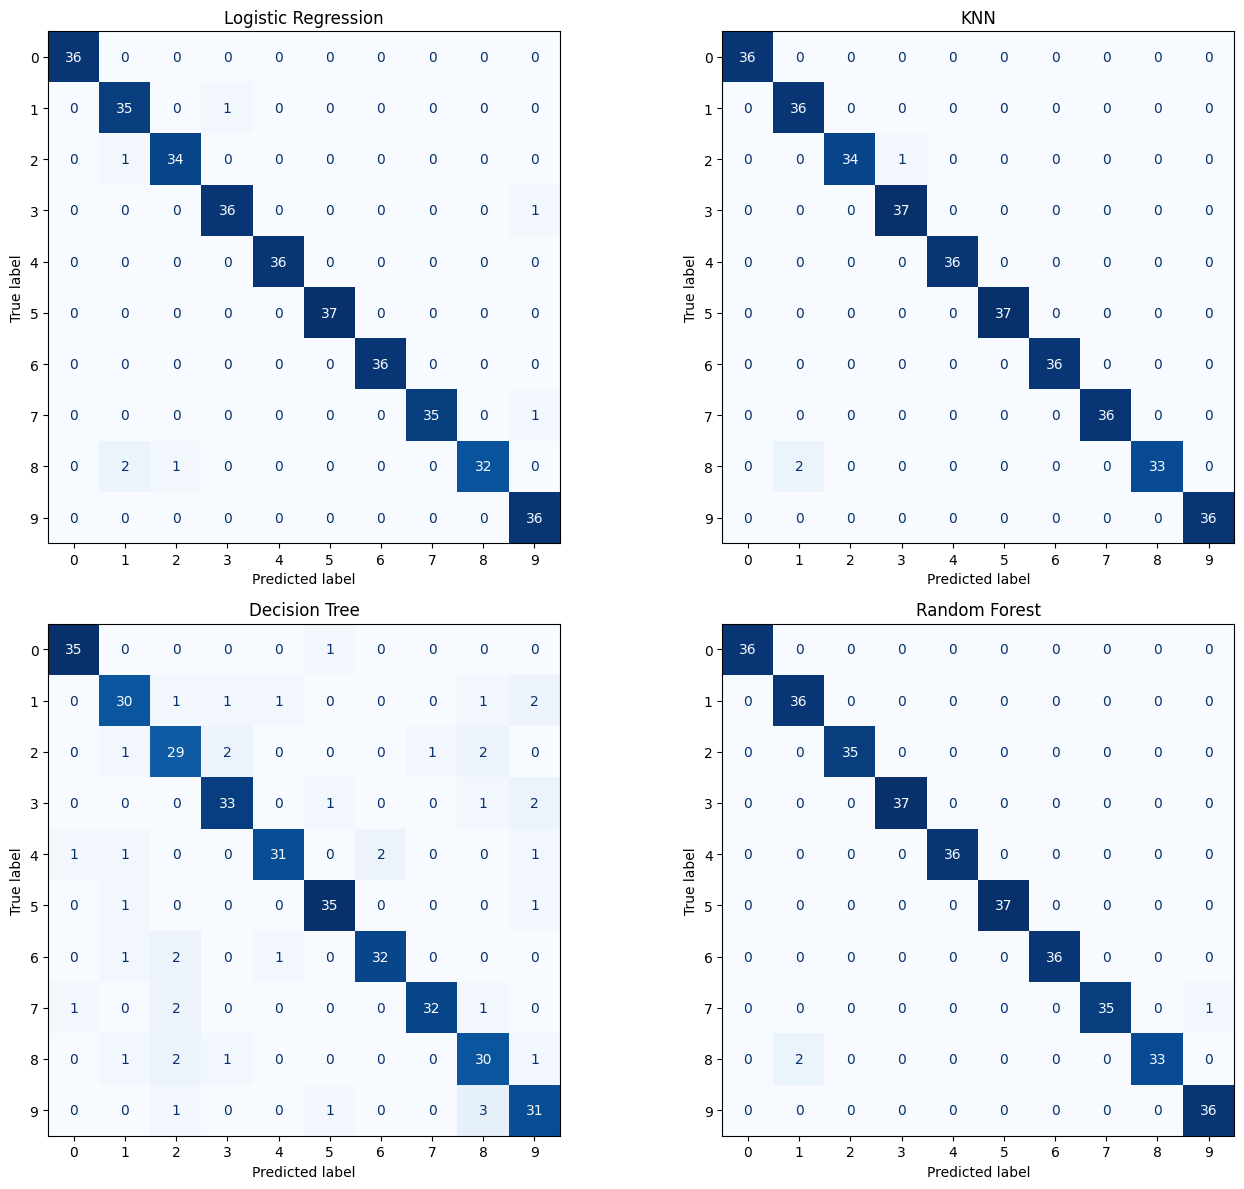

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (name, predictions) in zip(axes.flat, models.items()):

    cm = confusion_matrix(y_test, predictions, labels=np.arange(10))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=np.arange(10)
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

## Confusion Matrix Analysis

The confusion matrices reveal differences in the error patterns of the four classifiers.

KNN and Random Forest produced only three misclassifications each, while Logistic Regression made seven errors. Decision Tree performed considerably worse, with 42 misclassified samples.

For KNN, two errors involved confusing digit 8 with digit 1, while one digit 2 was classified as 3. Random Forest also confused two instances of digit 8 with digit 1, and misclassified one digit 7 as 9.

Logistic Regression showed more errors involving digit 8, while Decision Tree exhibited a broader distribution of classification errors across several classes.

Although KNN and Random Forest achieved identical accuracy, their confusion matrices show that they do not make exactly the same classification errors. This highlights the importance of examining class-level performance rather than relying exclusively on overall accuracy.

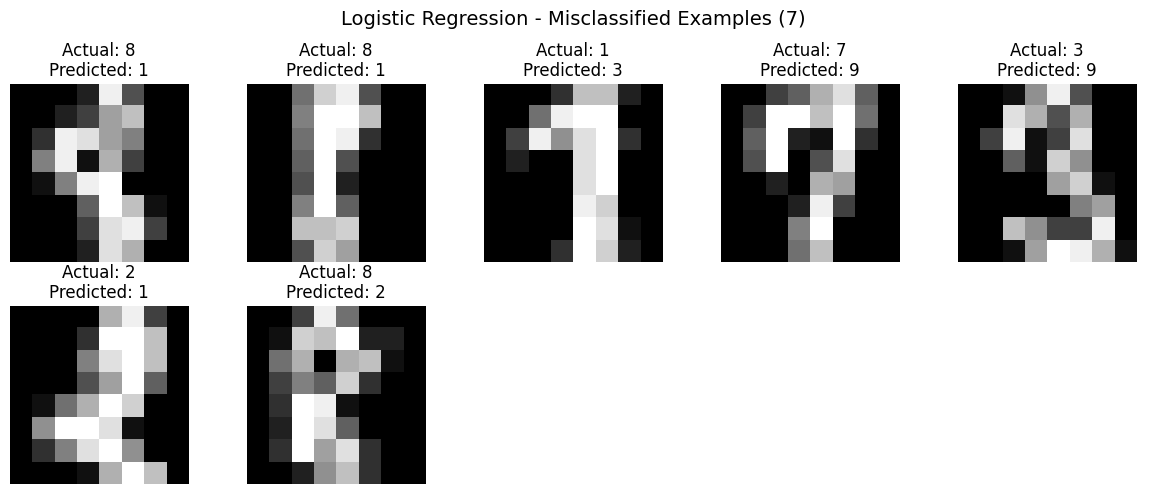

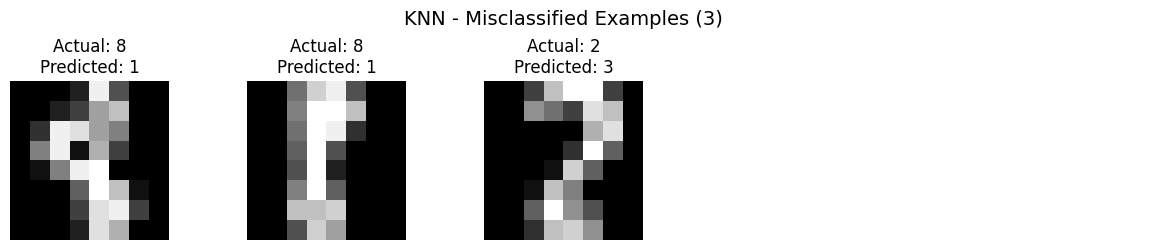

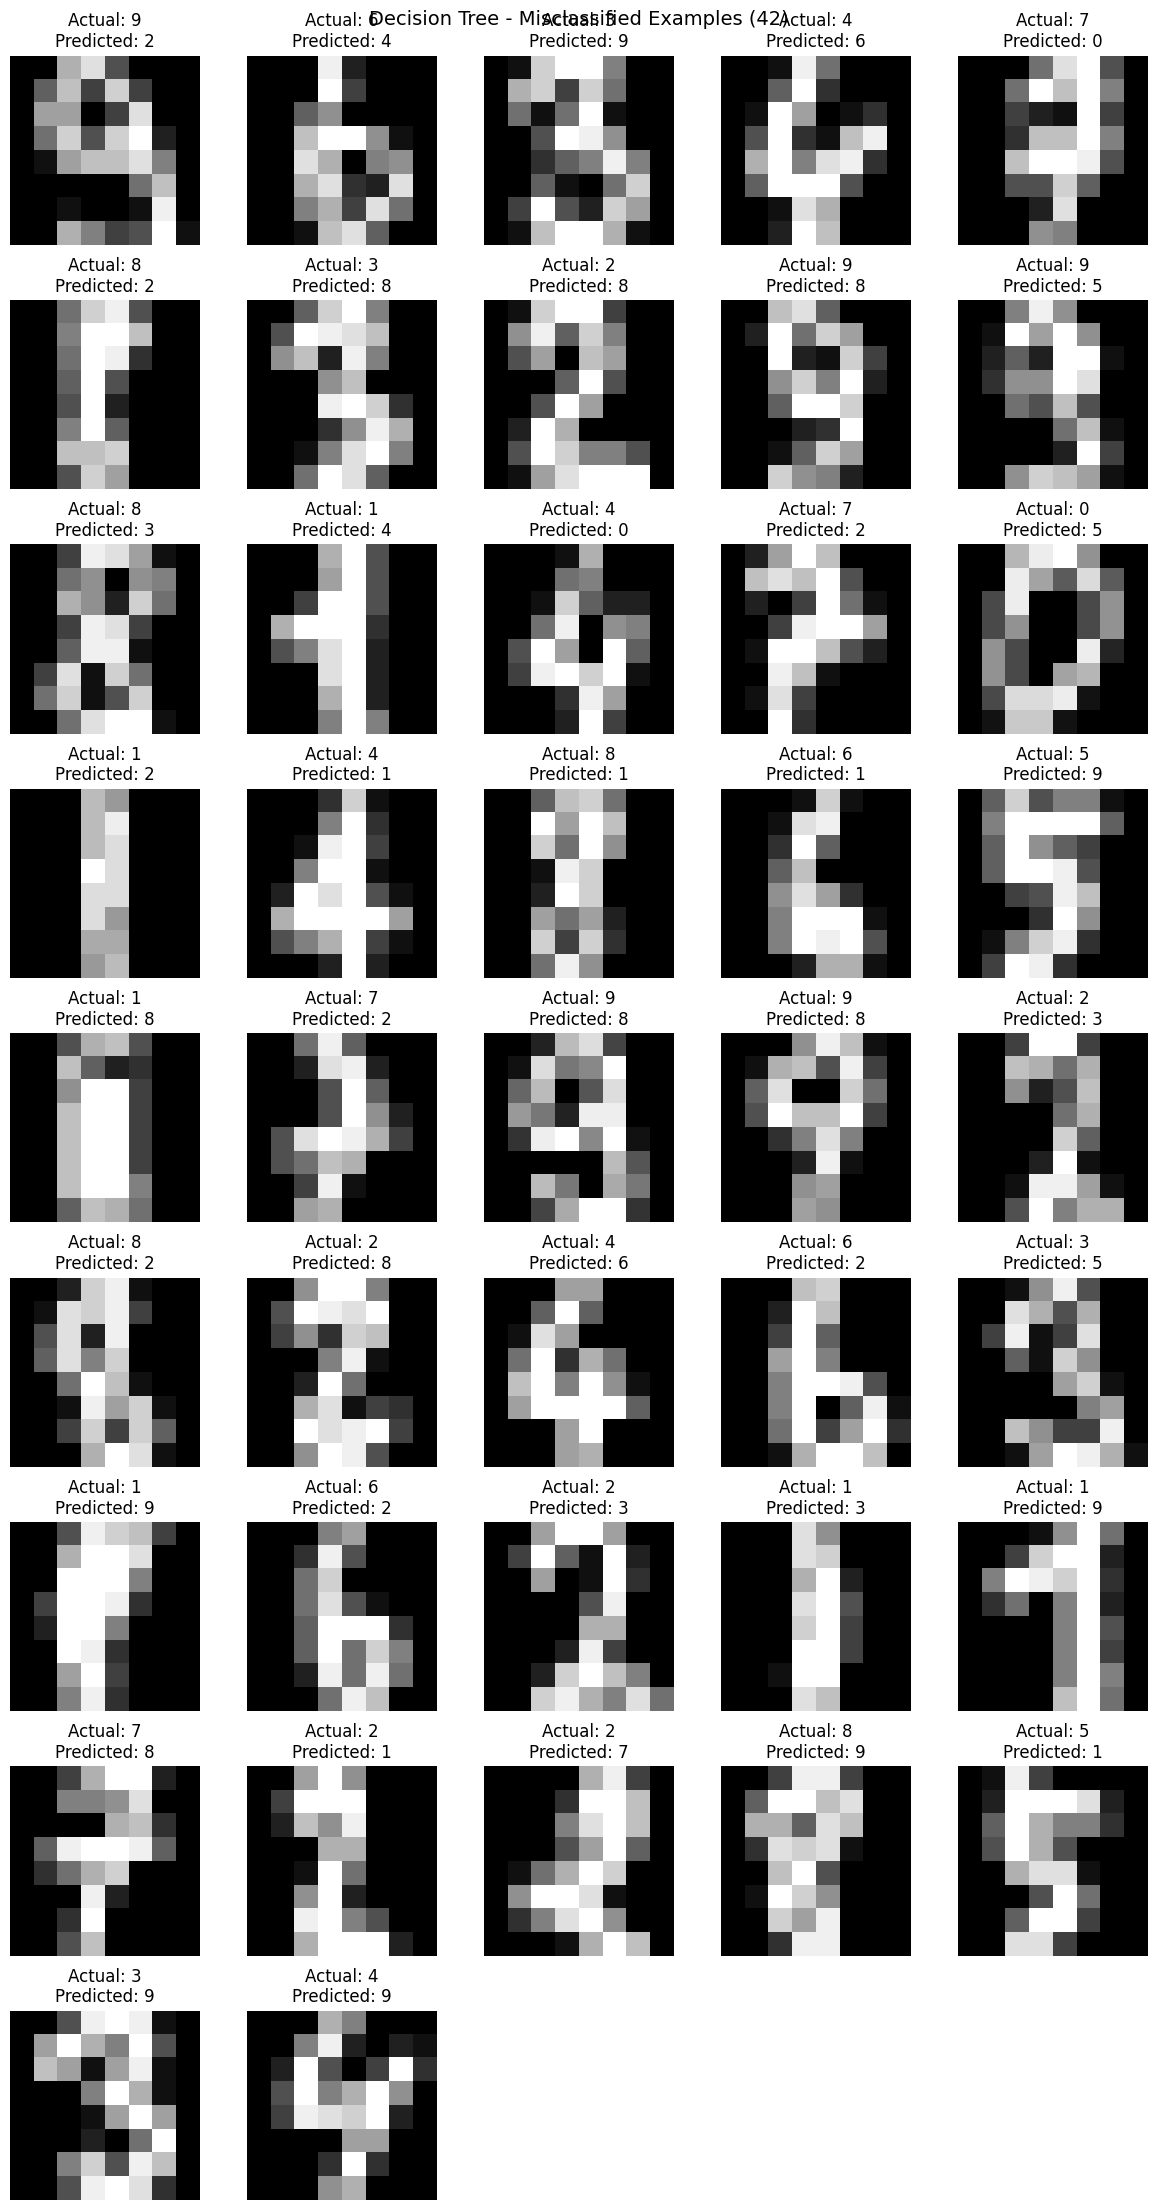

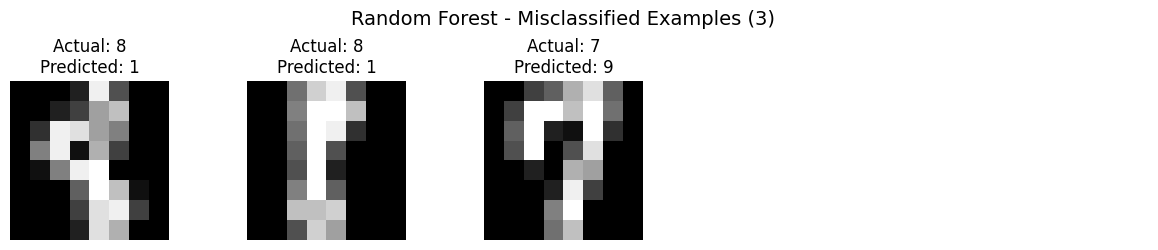

In [24]:
X_test_images = np.asarray(X_test).reshape(-1, 8, 8)
y_test_array = np.asarray(y_test)

for name, predictions in models.items():

    predictions = np.asarray(predictions)
    misclassified = np.where(y_test_array != predictions)[0]

    n_errors = len(misclassified)
    n_cols = 5
    n_rows = int(np.ceil(n_errors / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(12, 2.5 * n_rows),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, idx in zip(axes.flat, misclassified):

        ax.imshow(X_test_images[idx], cmap="gray")
        ax.set_title(
            f"Actual: {y_test_array[idx]}\nPredicted: {predictions[idx]}"
        )
        ax.axis("off")

    fig.suptitle(
        f"{name} - Misclassified Examples ({n_errors})",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

## Conclusion

This project investigated handwritten digit classification using four machine learning algorithms: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, and Random Forest.

Feature scaling experiments showed that its impact depends on the algorithm. Min-Max scaling slightly improved Logistic Regression, while KNN achieved the same accuracy on both original and Min-Max scaled data.

Among the four classifiers, KNN and Random Forest achieved the best performance, both reaching 99.17% accuracy and an F1-score of 99.16%. Logistic Regression also performed well, with 98.06% accuracy. Decision Tree achieved a lower accuracy of 88.33%, indicating that a single decision tree was less effective for this classification task.

The confusion matrices and misclassified examples revealed that certain handwritten digits, particularly 8 and 1, can be difficult to distinguish due to similarities in their visual patterns. Random Forest and KNN produced only three classification errors each, demonstrating strong performance across the ten classes.

Overall, the results highlight the effectiveness of distance-based methods and ensemble learning for handwritten digit recognition. However, since the evaluation was based on a single train-test split, cross-validation and hyperparameter tuning could provide a more reliable comparison of model performance.